<a href="https://colab.research.google.com/github/aruzhan2345/Employee-Attrition-Prediction-with-NN-DNN/blob/main/BDA_2407_Lab5_Aruzhan_Alimkhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5: Employee Attrition Prediction with NN/DNN
**Student:** Aruzhan Alimkhan:
**Group:** BDA-2407


## 1. Dataset
I chose [Employee Turnover by Davin Wijaya on Kaggle](https://www.kaggle.com/datasets/davinwijaya/employee-turnover) [1]. It contains real employee records originally shared by HR analyst Edward Babushkin. His [original 2017 post](https://edwvb.blogspot.com/2017/10/employee-turnover-how-to-predict-individual-risks-of-quitting.html) explicitly describes the data as real [2]. The employer, collection dates and sampling procedure are not disclosed, so I cannot independently audit how it was collected. The dataset is licensed CC BY-NC-SA 4.0.

The original file has 1,129 observations (rows) and 16 columns: the target `event` and 15 other columns. A feature is an input used to predict the target, the outcome we want to estimate. `event=1` means an observed departure; `event=0` means still employed at the last observation. The raw balance is 571 leave (50.58%) and 558 stay (49.42%).

Inputs describe age, gender, industry, profession, recruitment source (`traffic`), probation coaching, supervisor gender, wage reporting (`greywage`), commuting method (`way`) and five recorded personality scores. I keep category names as supplied instead of guessing the meaning of unexplained recruitment codes.

The original data was designed for survival analysis, which studies time until an event while allowing for people whose event has not yet been observed. Such incomplete follow-up is called right censoring. For this lab, I classify the recorded departure status. This is not a probability of leaving within a specified future period. I exclude `stag`, the duration until departure or last observation, from the predictors.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
url = "https://www.kaggle.com/api/v1/datasets/download/davinwijaya/employee-turnover"
df = pd.read_csv(url, compression="zip", encoding="cp1251")
print("Original shape:", df.shape)
display(df["event"].value_counts().rename("Count").to_frame().assign(
    Percent=df["event"].value_counts(normalize=True).mul(100).round(2)))

Original shape: (1129, 16)


,Count,Percent
event,,
1,571,50.58
0,558,49.42


## 2. Business understanding
I want to predict which employees are more likely to be recorded as leaving the company. HR managers could use a reliable version of this model to decide who might benefit from a supportive conversation about workload, training or career plans. The predictions should support a conversation, not become a reason to punish someone.

For this task, I think missing someone who leaves is more costly than checking in with someone who stays. A **false negative (FN)** is a leaver predicted to stay, so HR misses a chance to help. A **false positive (FP)** is a stayer predicted to leave, which can waste HR time. A **true positive (TP)** is a correctly identified leaver; a **true negative (TN)** is a correctly identified stayer.

I set these success criteria before training: **recall ≥ 0.75, F1 ≥ 0.65 and ROC-AUC ≥ 0.70**. These are my project targets, not established business requirements. Recall matters most, but I also want useful predictions rather than flagging everyone.

I will choose settings on the validation set. Among settings that meet all three targets, I will select the highest F1, then ROC-AUC. If none meets them, I will report the highest-F1 option as the best available model and state that validation success was not achieved.

## 3. Cleaning and feature engineering


In [ ]:
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip().replace("", np.nan)
df["profession"] = df["profession"].replace({"Finan\u0441e": "Finance"})
numeric_columns = ["stag", "event", "age", "extraversion", "independ", "selfcontrol", "anxiety", "novator"]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
print("Missing values before imputation:", int(df.isna().sum().sum()))
print("Exact duplicate rows removed:", int(df.duplicated().sum()))
df = df.dropna(subset=["event"]).drop_duplicates().copy()
df["event"] = df["event"].astype(int)
df = df.drop(columns="stag")
df["age_squared"] = df["age"] ** 2
print("Cleaned observations:", len(df), "| Input features:", df.shape[1] - 1)
display(df["event"].value_counts(normalize=True).mul(100).rename("Cleaned percent"))

Missing values before imputation: 0
Exact duplicate rows removed: 13
Cleaned observations: 1116 | Input features: 15


,Cleaned percent
event,
1,50.179211
0,49.820789


## 4. Exploratory data analysis (EDA)


In [ ]:
X = df.drop(columns="event")
y = df["event"]
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, stratify=y_holdout, random_state=SEED)
train = X_train.assign(event=y_train)
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))
print("Training shape:", train.shape)
display(train.dtypes.rename("Data type"))
display(y_train.value_counts().rename("Count").to_frame().assign(
    Percent=y_train.value_counts(normalize=True).mul(100).round(2)))

Train / validation / test: 669 223 224
Training shape: (669, 16)


,Data type
gender,object
age,float64
industry,object
profession,object
traffic,object
coach,object
head_gender,object
greywage,object
way,object
extraversion,float64


,Count,Percent
event,,
1,336,50.22
0,333,49.78


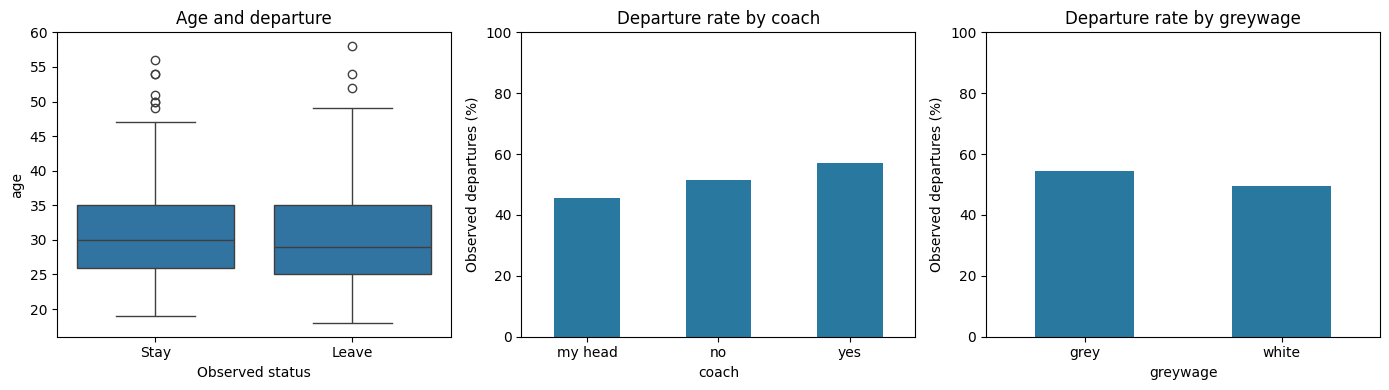

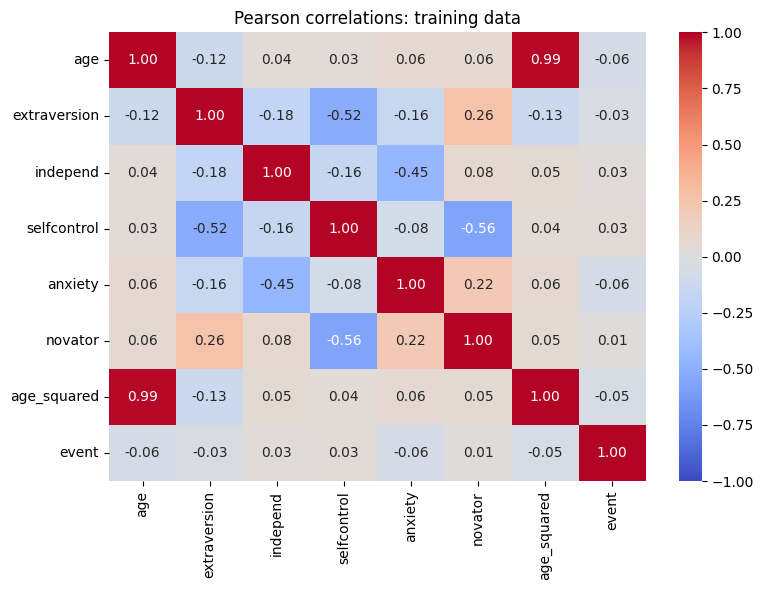

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=train, x="event", y="age", ax=axes[0])
axes[0].set(xticks=[0, 1], xticklabels=["Stay", "Leave"], xlabel="Observed status", title="Age and departure")
for ax, feature in zip(axes[1:], ["coach", "greywage"]):
    rates = train.groupby(feature)["event"].mean().mul(100)
    rates.plot.bar(ax=ax, rot=0, color="#2878a0")
    ax.set(ylabel="Observed departures (%)", title=f"Departure rate by {feature}", ylim=(0, 100))
plt.tight_layout()
plt.show()

correlations = train.select_dtypes(include="number").corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlations: training data")
plt.tight_layout()
plt.show()

In my training data, the median age was 30 for stayers and 29 for leavers, and the groups overlapped a lot. The departure rate was 45.5% for `my head`, 51.4% for `no` and 56.9% for `yes` in the coaching column. These differences do not show that coaching caused departures, because the groups may differ in other ways. The `grey` wage group had a 54.4% departure rate compared with 49.7% for `white`. All numeric features had weak linear correlations with departure: their absolute correlations were below 0.07. I therefore did not expect one numeric feature to explain the outcome by itself.

## 5. Preprocessing


In [ ]:
constant_columns = X_train.columns[X_train.nunique(dropna=False) <= 1].tolist()
print("Constant training features removed:", constant_columns)
X_train = X_train.drop(columns=constant_columns)
X_val = X_val.drop(columns=constant_columns)
X_test = X_test.drop(columns=constant_columns)
numeric = X_train.select_dtypes(include="number").columns
categorical = X_train.select_dtypes(include=["object", "string"]).columns
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical)
])
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
print("Inputs after preprocessing:", X_train_p.shape[1])

Constant training features removed: []
Inputs after preprocessing: 58


## 6. Training
Binary classification predicts one of two classes. Logistic regression is the linear baseline: it applies a sigmoid to a weighted sum of the inputs. A baseline is a simple model for comparison. Its default L2 regularization penalizes large squared coefficients to discourage overly complex fits.

In [ ]:
baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_p, y_train)

def train_network(units, learning_rate, class_weight=None):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(X_train_p.shape[1],))] +
                             [keras.layers.Dense(n, activation="relu") for n in units] +
                             [keras.layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy")
    history = model.fit(
        X_train_p, y_train, validation_data=(X_val_p, y_val),
        epochs=100, batch_size=32, class_weight=class_weight, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                  restore_best_weights=True)])
    return model, history.history

def scores(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    return {"Precision": precision_score(y_true, prediction, zero_division=0),
            "Recall": recall_score(y_true, prediction, zero_division=0),
            "F1": f1_score(y_true, prediction, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, probability)}

## 7. Tuning
### 7.1 Learning rate first
I first keep the DNN architecture fixed at 32 and 16 hidden neurons and try 0.00001, 0.001 and 0.1. These represent a very small step, a usual starting value, and a deliberately large step. The curves will show whether they are too slow or unstable in this run. I choose the rate with the lowest best validation loss.

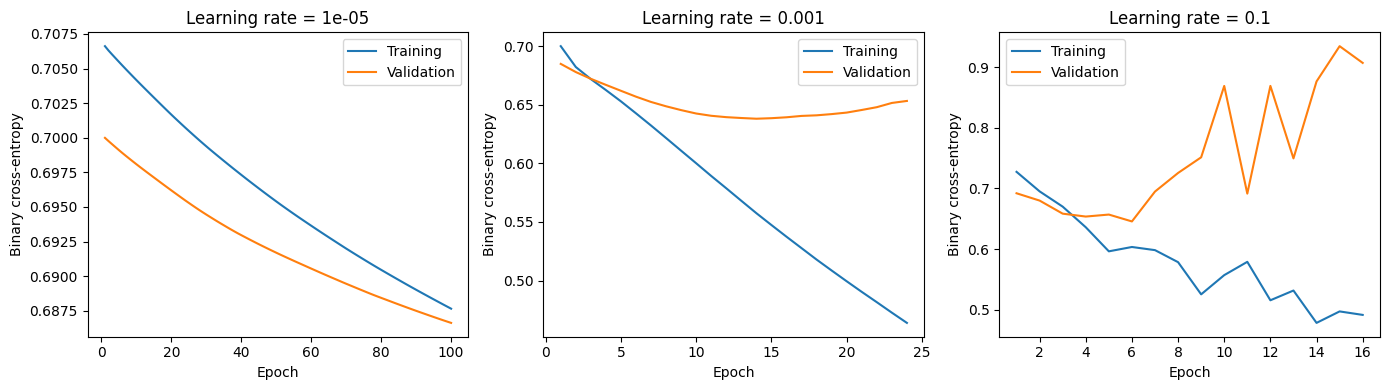

,Learning rate,Best validation loss,Epochs run
0,0.00001,0.686622,100
1,0.00100,0.638076,24
2,0.10000,0.645601,16


Selected learning rate: 0.001


In [ ]:
learning_rates = [0.00001, 0.001, 0.1]
lr_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, lr in zip(axes, learning_rates):
    model, history = train_network((32, 16), lr)
    lr_runs[lr] = (model, history)
    ax.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training")
    ax.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation")
    ax.set(title=f"Learning rate = {lr:g}", xlabel="Epoch", ylabel="Binary cross-entropy")
    ax.legend()
plt.tight_layout()
plt.show()
lr_table = pd.DataFrame([{"Learning rate": lr, "Best validation loss": min(h["val_loss"]),
                          "Epochs run": len(h["loss"])} for lr, (_, h) in lr_runs.items()])
display(lr_table)
best_lr = min(lr_runs, key=lambda lr: min(lr_runs[lr][1]["val_loss"]))
print("Selected learning rate:", best_lr)

### 7.2 Layer and neuron counts
I keep the selected learning rate and compare two one-layer NNs, with 16 or 32 neurons, and two DNNs, with (16, 8) or (32, 16) neurons. I choose the highest validation ROC-AUC within each family, keeping both families for the required final comparison. Each run starts from the same random seed. Smaller networks and EarlyStopping are the changes I test to limit overfitting.

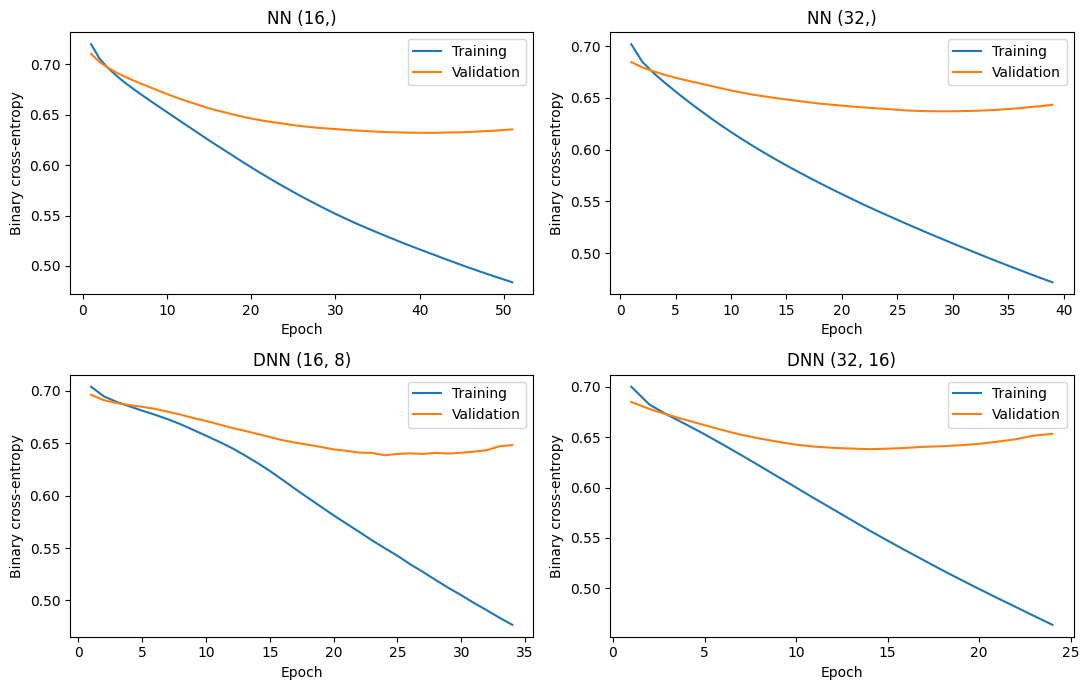

,Model,Hidden neurons,Precision,Recall,F1,ROC-AUC
0,NN,"(16,)",0.587,0.571,0.579,0.681
1,NN,"(32,)",0.618,0.607,0.613,0.682
2,DNN,"(16, 8)",0.618,0.562,0.589,0.675
3,DNN,"(32, 16)",0.640,0.634,0.637,0.679


In [ ]:
architectures = {"NN": [(16,), (32,)], "DNN": [(16, 8), (32, 16)]}
architecture_runs = {}
architecture_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (family, units) in zip(axes.flat, [(f, u) for f, values in architectures.items() for u in values]):
    model, history = lr_runs[best_lr] if units == (32, 16) else train_network(units, best_lr)
    architecture_runs[units] = (model, history)
    probability = model.predict(X_val_p, verbose=0).ravel()
    architecture_rows.append({"Model": family, "Hidden neurons": units, **scores(y_val, probability)})
    ax.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training")
    ax.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation")
    ax.set(title=f"{family} {units}", xlabel="Epoch", ylabel="Binary cross-entropy")
    ax.legend()
plt.tight_layout()
plt.show()
architecture_table = pd.DataFrame(architecture_rows)
display(architecture_table.round(3))
selected_units = {family: architecture_table[architecture_table["Model"] == family]
                  .sort_values("ROC-AUC", ascending=False).iloc[0]["Hidden neurons"]
                  for family in architectures}

**What I found:** the learning rate of 0.00001 learned too slowly: even after 100 epochs, its validation loss was 0.687, close to the 0.693 loss from predicting 0.5 for everyone. This suggests underfitting within the available training time. The rate of 0.1 gave an unstable validation curve and ended at 0.907. I selected 0.001, which reached the lowest validation loss, 0.638 at epoch 14, in the learning-rate experiment.

At 0.001, training loss continued falling after validation loss started rising. This is evidence of overfitting. I tested smaller layer sizes and used EarlyStopping to restore the best epoch instead of keeping the final weights. The smaller networks did not improve validation ROC-AUC, so I kept 32 neurons for the NN and 32 → 16 for the DNN. Their unweighted validation ROC-AUC values were 0.682 and 0.679. EarlyStopping limits overfitting, but the curves show it does not remove the problem completely.

### 7.3 Class imbalance


In [ ]:
class_weights = (len(y_train) / (2 * y_train.value_counts())).to_dict()
print("Training class weights:", class_weights)
models = {"Logistic Regression": baseline}
weight_rows = []
for family, units in selected_units.items():
    plain_model = architecture_runs[units][0]
    weighted_model, _ = train_network(units, best_lr, class_weights)
    candidates = [("Unweighted", plain_model), ("Balanced", weighted_model)]
    best_auc = -1
    for weighting, model in candidates:
        result = scores(y_val, model.predict(X_val_p, verbose=0).ravel())
        weight_rows.append({"Model": family, "Weighting": weighting, **result})
        if result["ROC-AUC"] > best_auc:
            best_auc = result["ROC-AUC"]
            models[family] = model
weight_table = pd.DataFrame(weight_rows)
display(weight_table.round(3))
for family in ["NN", "DNN"]:
    print(f"Selected {family}, hidden neurons: {selected_units[family]}")
    models[family].summary()
    units = selected_units[family][0]
    print(f"First dense layer: ({X_train_p.shape[1]} inputs + 1 bias) × {units} neurons = "
          f"{(X_train_p.shape[1] + 1) * units} trainable parameters.")

Training class weights: {1: 0.9955357142857143, 0: 1.0045045045045045}


,Model,Weighting,Precision,Recall,F1,ROC-AUC
0,NN,Unweighted,0.618,0.607,0.613,0.682
1,NN,Balanced,0.620,0.598,0.609,0.681
2,DNN,Unweighted,0.640,0.634,0.637,0.679
3,DNN,Balanced,0.645,0.634,0.640,0.679


Selected NN, hidden neurons: (32,)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 32)             │         1,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,765 (22.52 KB)

... (7 outputs left out)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,868 (19.02 KB)

First dense layer: (58 inputs + 1 bias) × 32 neurons = 1888 trainable parameters.


## 8. Evaluation
### 8.1 Choose thresholds using validation data
I compare 0.3, 0.5 and 0.7 for each model on validation data. ROC-AUC stays the same across thresholds because it uses probability rankings, not the resulting 0/1 decisions. The selection rule is the one stated in Section 2. I lock one threshold per model and one preferred model before accessing test predictions.

In [ ]:
threshold_rows = []
for name, model in models.items():
    probability = (model.predict_proba(X_val_p)[:, 1] if name == "Logistic Regression"
                   else model.predict(X_val_p, verbose=0).ravel())
    for threshold in [0.3, 0.5, 0.7]:
        threshold_rows.append({"Model": name, "Threshold": threshold, **scores(y_val, probability, threshold)})
threshold_table = pd.DataFrame(threshold_rows)
threshold_table["Meets criteria"] = ((threshold_table["Recall"] >= 0.75) &
                                    (threshold_table["F1"] >= 0.65) &
                                    (threshold_table["ROC-AUC"] >= 0.70))
display(threshold_table.round(3))
ranked = threshold_table.sort_values(["Meets criteria", "F1", "ROC-AUC"], ascending=False)
chosen_thresholds = ranked.drop_duplicates("Model").set_index("Model")["Threshold"].to_dict()
preferred_model = ranked.iloc[0]["Model"]
print("Locked thresholds:", chosen_thresholds)
print("Preferred model from validation:", preferred_model)

,Model,Threshold,Precision,Recall,F1,ROC-AUC,Meets criteria
0,Logistic Regression,0.3,0.552,0.902,0.685,0.668,False
1,Logistic Regression,0.5,0.617,0.589,0.603,0.668,False
2,Logistic Regression,0.7,0.800,0.214,0.338,0.668,False
3,NN,0.3,0.552,0.902,0.685,0.682,False
4,NN,0.5,0.618,0.607,0.613,0.682,False
5,NN,0.7,0.773,0.304,0.436,0.682,False
6,DNN,0.3,0.533,0.946,0.682,0.679,False
7,DNN,0.5,0.645,0.634,0.640,0.679,False
8,DNN,0.7,0.839,0.232,0.364,0.679,False


Locked thresholds: {'NN': 0.3, 'Logistic Regression': 0.3, 'DNN': 0.3}
Preferred model from validation: NN


### 8.2 Final test evaluation
This is the first and only test prediction step. I use the previously chosen models and thresholds without adjusting them after seeing these results. A confusion matrix counts actual versus predicted classes: its rows are the true classes, and columns are predicted classes. The comparison table reports the four requested metrics.

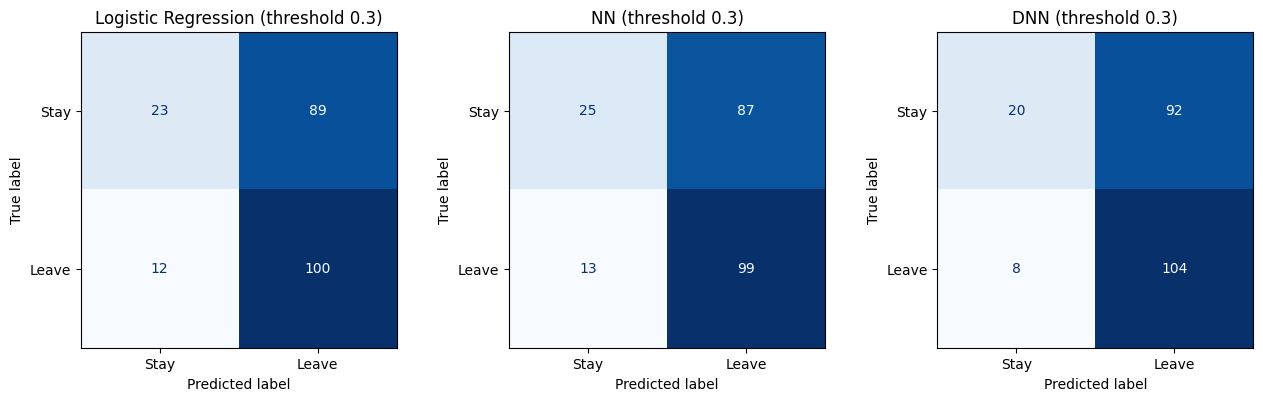

,Threshold,Precision,Recall,F1,ROC-AUC,Meets criteria
Model,,,,,,
Logistic Regression,0.3,0.529,0.893,0.664,0.583,False
NN,0.3,0.532,0.884,0.664,0.637,False
DNN,0.3,0.531,0.929,0.675,0.632,False


Model selected before testing: NN


In [ ]:
X_test_p = preprocessor.transform(X_test).astype("float32")
test_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, models.items()):
    probability = (model.predict_proba(X_test_p)[:, 1] if name == "Logistic Regression"
                   else model.predict(X_test_p, verbose=0).ravel())
    threshold = chosen_thresholds[name]
    prediction = (probability >= threshold).astype(int)
    test_rows.append({"Model": name, "Threshold": threshold, **scores(y_test, probability, threshold)})
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=["Stay", "Leave"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (threshold {threshold})")
plt.tight_layout()
plt.show()
comparison = pd.DataFrame(test_rows).set_index("Model")
comparison["Meets criteria"] = ((comparison["Recall"] >= 0.75) & (comparison["F1"] >= 0.65) &
                                (comparison["ROC-AUC"] >= 0.70))
display(comparison.round(3))
print("Model selected before testing:", preferred_model)

## 9. Conclusion
For this run, I chose the **NN with one hidden layer of 32 neurons and a threshold of 0.3**. No model met every validation target, so I used my fallback rule. The NN tied logistic regression on validation F1 (0.685) and had the higher ROC-AUC (0.682 versus 0.668). I kept this choice when I moved to the test set.

On the test set, the NN achieved **precision 0.532, recall 0.884, F1 0.664 and ROC-AUC 0.637**. It met my recall and F1 targets but missed the ROC-AUC target of 0.70, so the overall success criteria were **not met**. It found 99 of the 112 leavers, but it also incorrectly flagged 87 of the 112 stayers. This shows why high recall alone is not enough.

The DNN did beat the logistic baseline on test recall (0.929 versus 0.893), F1 (0.675 versus 0.662) and ROC-AUC (0.632 versus 0.583). However, its ROC-AUC was slightly below the NN's, and it had 2,433 learned parameters compared with the NN's 1,921. For this small dataset, I do not think the extra layer gives a convincing practical advantage. I would keep the NN as the best available choice under my validation rule, but none of these models is ready for real HR decisions.

My main findings were that the numeric relationships with departure were weak, class weighting made little difference, and a lower threshold found more leavers at the cost of many false alarms.

**Limitations:**
1. The sample is small, the collection procedure is not fully documented, and there are no employee IDs. Some employees have identical predictor profiles even after exact source duplicates are removed; I cannot verify whether these are different people or repeated records. This limits confidence in how well a random split represents new employees.
2. Employees were observed for different lengths of time. A person labeled stay could leave later, so this experiment does not establish future departure risk over a fixed period.

**Next steps:**
1. Collect more employee records with unique IDs, a common prediction date, a fixed follow-up period, and useful information recorded before departure, such as workload or satisfaction.
2. Evaluate the chosen model on a later, independent sample and compare missed departures and false alarms across employee groups before considering an HR pilot.

## 10. References
1. Wijaya, D. (2020). **Employee Turnover**. Kaggle. Original data by Edward Babushkin; CC BY-NC-SA 4.0. https://www.kaggle.com/datasets/davinwijaya/employee-turnover
2. Babushkin, E. (2017). **Employee turnover: how to predict individual risks of quitting**. Original data provenance and variable descriptions. https://edwvb.blogspot.com/2017/10/employee-turnover-how-to-predict-individual-risks-of-quitting.html
3. Scikit-learn. **LogisticRegression**. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
4. Keras. **The Sequential model** and **Dense layer**. https://keras.io/guides/sequential_model/ ; https://keras.io/api/layers/core_layers/dense/
5. Keras. **Layer activation functions**. https://keras.io/api/layers/activations/
6. Keras. **BinaryCrossentropy**. https://keras.io/api/losses/probabilistic_losses/#binarycrossentropy-class
7. Keras. **Adam**. https://keras.io/api/optimizers/adam/
8. Keras. **EarlyStopping**. https://keras.io/api/callbacks/early_stopping/
9. Scikit-learn. **compute_class_weight**: balanced class-weight formula. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html